# Steam Reviews 2021 — Data Mining Final Project
## Notebook 02 · Part 1, section 4: Exploratory Data Analysis

| Subsection | Assignment requirement |
|---|---|
| 4.1 | Summary statistics |
| 4.2 | Feature distributions |
| 4.3 | Correlation analysis |
| 4.4 | Meaningful visualizations (figures 07–18 in this notebook, more than five) |
| 4.5 | ANOVA and other statistical tests (hypotheses H1–H3 from section 1.3) |
| 4.6 | At least five important conclusions |

**Input:** `data/processed/train.parquet` created by notebook 01.

**Why only the training set?** Validation and test sets imitate unseen future data. If we looked at them during EDA, our later decisions (features, transformations, model choice) would be influenced by data that must stay unseen, and the final test score would be optimistic. All conclusions below are therefore drawn from the training set only.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src import config as C
from src import eda as E
from src.features import word_count

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid", context="notebook")
C.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
C.TABLES_DIR.mkdir(parents=True, exist_ok=True)

NEG, POS = "Not recommended", "Recommended"
PALETTE = {NEG: "#c0392b", POS: "#27ae60"}
ALPHA = 0.05


def savefig(name):
    plt.tight_layout()
    plt.savefig(C.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def plot_rate(ax, table, overall, title, xlabel, rotate=0):
    x = np.arange(len(table))
    rate = table["rate"].to_numpy() * 100
    err = np.vstack([rate - table["ci_low"].to_numpy() * 100, table["ci_high"].to_numpy() * 100 - rate])
    ax.bar(x, rate, color="#c0392b", alpha=0.8)
    ax.errorbar(x, rate, yerr=err, fmt="none", ecolor="black", capsize=3, lw=1)
    ax.axhline(overall * 100, ls="--", color="grey", lw=1, label=f"overall {overall:.1%}")
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in table.index], rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylabel("% negative reviews")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(loc="upper right")


print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")

python 3.12.1 | pandas 3.1.1 | numpy 2.5.5


In [2]:
train = pd.read_parquet(C.DATA_PROCESSED / "train.parquet")
df = train.copy()
df["is_negative"] = (df[C.TARGET] == 0).astype(int)
df["label"] = np.where(df[C.TARGET] == 1, POS, NEG)
df["word_count"] = word_count(df[C.TEXT_CLEAN])
df["playtime_at_review_h"] = df["author_playtime_at_review"] / 60
df["playtime_forever_h"] = df["author_playtime_forever"] / 60
df["playtime_last_two_weeks_h"] = df["author_playtime_last_two_weeks"] / 60

overall_neg = df["is_negative"].mean()
print(f"Training set: {len(df):,} reviews, {df['app_name'].nunique()} games, "
      f"{df['created_at'].min():%Y-%m-%d} ... {df['created_at'].max():%Y-%m-%d}")
print(f"Negative share: {overall_neg:.2%}")

Training set: 132,350 reviews, 315 games, 2010-11-21 ... 2021-01-23
Negative share: 10.97%


## 4.1 Summary statistics

### 4.1.1 Numeric features
`word_count` (number of words in the cleaned review) and playtime in hours are added only to make the analysis readable; they are formally created as features in section 5.

In [3]:
NUMERIC = [
    "author_num_games_owned",
    "author_num_reviews",
    "playtime_at_review_h",
    "playtime_forever_h",
    "playtime_last_two_weeks_h",
    "votes_helpful",
    "votes_funny",
    "comment_count",
    "weighted_vote_score",
    "word_count",
]
summary = df[NUMERIC].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T
summary.insert(0, "missing_%", 100 * df[NUMERIC].isna().mean())
summary["skew"] = df[NUMERIC].skew()
summary["kurtosis"] = df[NUMERIC].kurtosis()
summary["mean/median"] = summary["mean"] / summary["50%"].replace(0, np.nan)
summary.to_csv(C.TABLES_DIR / "eda_summary_numeric.csv")
display(summary.round(2))

heavy = summary.index[summary["skew"] > 1].tolist()
print(f"Observation: {len(heavy)} of {len(NUMERIC)} numeric features have skewness > 1 "
      f"(strongest: {summary['skew'].idxmax()}, skew = {summary['skew'].max():.1f}). "
      "Their means are far above their medians, so medians and log scales are used below.")

,missing_%,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,kurtosis,mean/median
author_num_games_owned,0.0,132350.0,165.59,299.36,0.0,31.25,85.00,192.00,565.00,1246.51,16821.00,11.72,317.04,1.95
author_num_reviews,0.0,132350.0,11.85,31.97,1.0,2.00,5.00,11.00,43.00,108.00,2627.00,24.61,1209.99,2.37
playtime_at_review_h,0.0,132350.0,151.24,430.07,0.0,9.75,32.00,113.90,675.40,1859.03,28251.63,11.96,330.56,4.73
playtime_forever_h,0.0,132350.0,271.42,676.77,0.0,21.17,70.37,240.90,1173.79,2921.99,39611.33,10.65,258.22,3.86
playtime_last_two_weeks_h,0.0,132350.0,2.67,12.59,0.0,0.00,0.00,0.00,14.72,58.33,334.90,9.66,138.39,NaN
votes_helpful,0.0,132350.0,1.81,38.26,0.0,0.00,0.00,1.00,3.00,17.00,8016.00,107.13,17372.06,NaN
votes_funny,0.0,132345.0,0.78,29.05,0.0,0.00,0.00,0.00,1.00,5.00,5872.00,129.39,21449.64,NaN
comment_count,0.0,132350.0,0.14,3.41,0.0,0.00,0.00,0.00,0.00,3.00,1026.00,218.64,62820.13,NaN
weighted_vote_score,0.0,132350.0,0.17,0.24,0.0,0.00,0.00,0.48,0.53,0.60,0.97,0.77,-1.29,NaN
word_count,0.0,132350.0,39.75,91.92,1.0,4.00,12.00,36.00,167.00,443.00,1777.00,6.68,64.94,3.31


Observation: 9 of 10 numeric features have skewness > 1 (strongest: comment_count, skew = 218.6). Their means are far above their medians, so medians and log scales are used below.


### 4.1.2 Numeric features by class

In [4]:
by_class = df.groupby("label")[NUMERIC].median().T
by_class["ratio neg/pos"] = by_class[NEG] / by_class[POS].replace(0, np.nan)
by_class = by_class[[NEG, POS, "ratio neg/pos"]]
by_class.columns.name = "median"
display(by_class.round(2))

median,Not recommended,Recommended,ratio neg/pos
author_num_games_owned,118.00,81.00,1.46
author_num_reviews,6.00,5.00,1.20
playtime_at_review_h,24.30,32.75,0.74
playtime_forever_h,46.12,73.17,0.63
playtime_last_two_weeks_h,0.00,0.00,NaN
votes_helpful,1.00,0.00,NaN
votes_funny,0.00,0.00,NaN
comment_count,0.00,0.00,NaN
weighted_vote_score,0.46,0.00,NaN
word_count,29.00,10.00,2.90


Medians are compared instead of means because of the heavy tails. A ratio far from 1 means that the feature differs between negative and positive reviews; whether the difference is statistically reliable is tested in 4.5.

### 4.1.3 Boolean and categorical features

In [5]:
bool_rows = []
for col in C.BOOL_FEATURES:
    s = df[col]
    bool_rows.append({
        "feature": col,
        "share of 1 (%)": 100 * s.mean(),
        "missing": int(s.isna().sum()),
        "% negative when 1": 100 * df.loc[s == 1, "is_negative"].mean(),
        "% negative when 0": 100 * df.loc[s == 0, "is_negative"].mean(),
    })
bool_summary = pd.DataFrame(bool_rows).set_index("feature")
display(bool_summary.round(2))

game_counts = df["app_name"].value_counts()
print(f"Games: {len(game_counts)}; reviews per game: median {game_counts.median():,.0f}, "
      f"min {game_counts.min():,}, max {game_counts.max():,}")
print(f"Top-10 games cover {100 * game_counts.head(10).sum() / len(df):.1f}% of the training reviews")
display(game_counts.head(10).rename("reviews").to_frame()
        .assign(**{"share_%": lambda d: (100 * d["reviews"] / len(df)).round(2)}))

,share of 1 (%),missing,% negative when 1,% negative when 0
feature,,,,
steam_purchase,77.48,0,10.63,12.17
received_for_free,2.96,0,10.27,11.00
written_during_early_access,10.08,0,13.36,10.71


Games: 315; reviews per game: median 153, min 1, max 5,175
Top-10 games cover 30.1% of the training reviews


,reviews,share_%
app_name,,
Tom Clancy's Rainbow Six Siege,5175,3.91
Terraria,5043,3.81
Garry's Mod,4480,3.38
PLAYERUNKNOWN'S BATTLEGROUNDS,4441,3.36
Grand Theft Auto V,4247,3.21
Among Us,4209,3.18
Rust,3841,2.90
Rocket League,3356,2.54
PAYDAY 2,2557,1.93


The boolean features are unbalanced themselves (most reviews are Steam purchases; free copies and early-access reviews are rare), so their effect is judged by the negative rate inside each group, not by raw counts. The game column has many levels with very different sizes, which is why rare games are grouped in the one-hot encoding (notebook 01, section 3.11).

### 4.1.4 Text length

In [6]:
text_stats = df.groupby("label")["word_count"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
display(text_stats.round(1))
short = (df["word_count"] <= 3).mean()
print(f"Observation: {short:.1%} of all reviews have at most 3 words; "
      f"the longest review has {df['word_count'].max():,.0f} words.")

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
label,,,,,,,,,,,
Not recommended,14525.0,75.6,137.9,1.0,3.0,9.0,29.0,81.0,185.0,713.8,1529.0
Recommended,117825.0,35.3,83.5,1.0,2.0,3.0,10.0,31.0,83.0,400.0,1777.0


Observation: 24.2% of all reviews have at most 3 words; the longest review has 1,777 words.


## 4.2 Feature distributions
### Figure 07 — class distribution in the training set

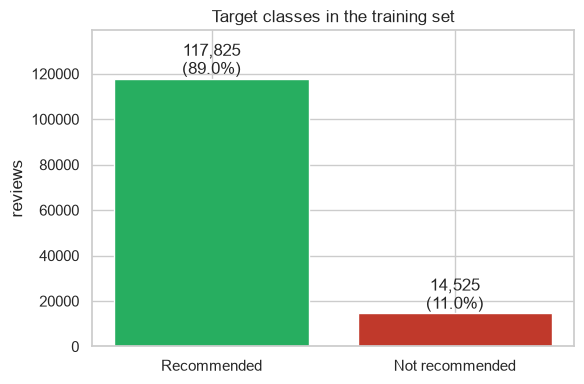

Observation: 8.1 positive reviews per negative review.


In [7]:
counts = df["label"].value_counts().reindex([POS, NEG])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[POS], PALETTE[NEG]])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}\n({value / len(df):.1%})",
            ha="center", va="bottom")
ax.set_ylabel("reviews")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Target classes in the training set")
savefig("07_class_balance_train")
print(f"Observation: {counts[POS] / counts[NEG]:.1f} positive reviews per negative review.")

The target is strongly imbalanced, exactly as in the full dataset (notebook 01, section 2.5). A model that always predicts *Recommended* would reach an accuracy equal to the positive share while detecting zero negative reviews, so the project evaluates models with F1-macro and PR-AUC of the negative class.

### Figure 08 — distributions of numeric features on the log scale, by class

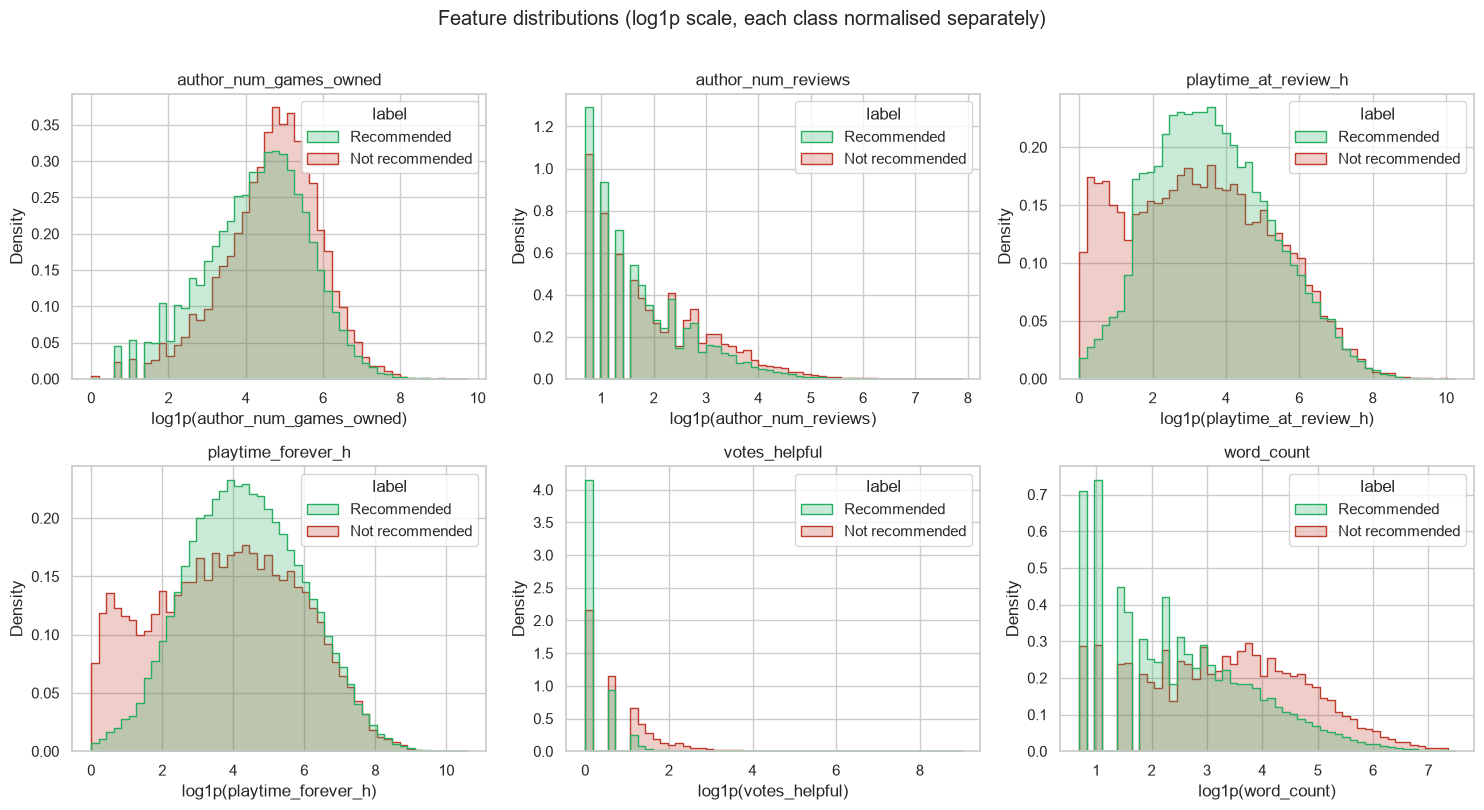

In [8]:
DIST = ["author_num_games_owned", "author_num_reviews", "playtime_at_review_h",
        "playtime_forever_h", "votes_helpful", "word_count"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), DIST):
    tmp = pd.DataFrame({"value": np.log1p(df[col]), "label": df["label"]}).dropna()
    sns.histplot(data=tmp, x="value", hue="label", hue_order=[POS, NEG], palette=PALETTE,
                 stat="density", common_norm=False, element="step", bins=50, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(f"log1p({col})")
fig.suptitle("Feature distributions (log1p scale, each class normalised separately)", y=1.01)
savefig("08_numeric_distributions_by_class")

On the raw scale these features are concentrated near zero with a long right tail (see the skewness in 4.1.1); after `log1p` they become roughly bell-shaped, which supports the log transformation used in the pipeline. Each class is normalised separately, so a horizontal shift between the red and the green curve means the typical value differs between classes, independently of the class imbalance.

### Figure 09 — review length by class

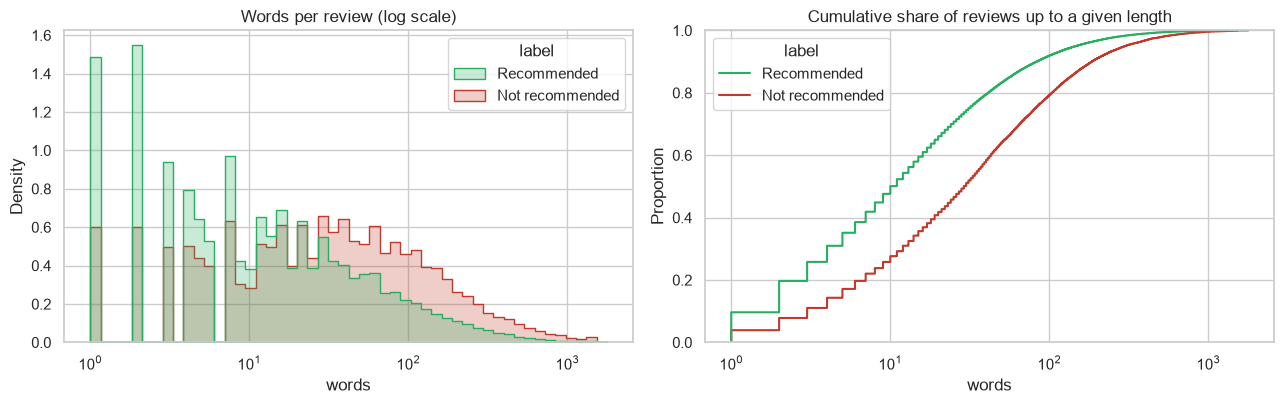

Observation: median length 29 words (negative) vs 10 words (positive); 'Not recommended' reviews are longer in the middle of the distribution.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(data=df, x="word_count", hue="label", hue_order=[POS, NEG], palette=PALETTE,
             stat="density", common_norm=False, element="step", bins=50, log_scale=True, ax=axes[0])
axes[0].set_title("Words per review (log scale)")
axes[0].set_xlabel("words")
sns.ecdfplot(data=df, x="word_count", hue="label", hue_order=[POS, NEG], palette=PALETTE,
             log_scale=True, ax=axes[1])
axes[1].set_title("Cumulative share of reviews up to a given length")
axes[1].set_xlabel("words")
savefig("09_review_length_by_class")

med = df.groupby("label")["word_count"].median()
longer = NEG if med[NEG] > med[POS] else POS
print(f"Observation: median length {med[NEG]:.0f} words (negative) vs {med[POS]:.0f} words (positive); "
      f"'{longer}' reviews are longer in the middle of the distribution.")

The cumulative curve shows the share of reviews that are not longer than *x* words; the curve that lies further to the right belongs to the class with longer reviews. Length is a candidate feature for section 5 and the basis of hypothesis H2.

## 4.3 Correlation analysis
### Figure 10 — Spearman correlation matrix
Spearman's ρ is used as the main coefficient because it measures **monotonic** relations on ranks and is not dominated by a few extreme values. Post-publication columns are included to show what they are related to, even though they are excluded from the model (leakage, notebook 01 section 3.9).

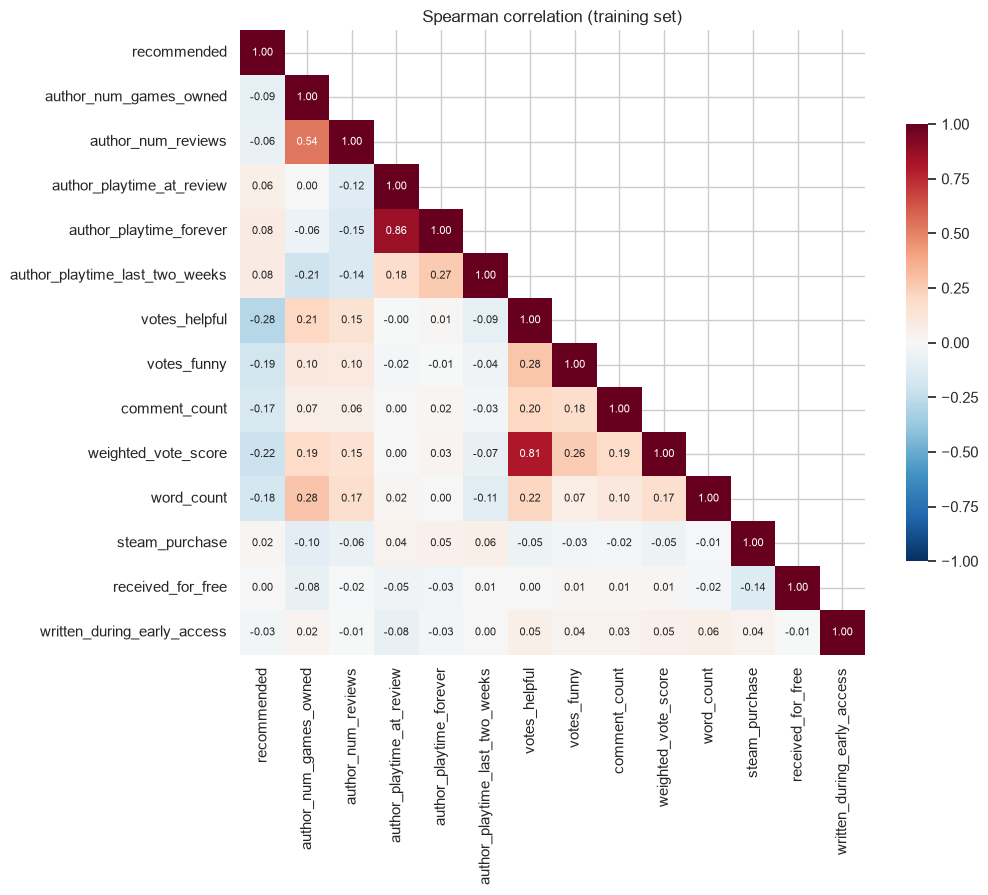

Feature pairs with |rho| >= 0.5:


,feature_a,feature_b,rho
0,author_playtime_at_review,author_playtime_forever,0.863
1,votes_helpful,weighted_vote_score,0.809
2,author_num_games_owned,author_num_reviews,0.535


In [10]:
CORR = ["recommended", "author_num_games_owned", "author_num_reviews", "author_playtime_at_review",
        "author_playtime_forever", "author_playtime_last_two_weeks", "votes_helpful", "votes_funny",
        "comment_count", "weighted_vote_score", "word_count",
        "steam_purchase", "received_for_free", "written_during_early_access"]
spearman = df[CORR].corr(method="spearman")
spearman.to_csv(C.TABLES_DIR / "eda_spearman_matrix.csv")

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
sns.heatmap(spearman, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.7}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation (training set)")
savefig("10_spearman_correlation")

pairs = E.strong_pairs(spearman.drop(index="recommended", columns="recommended"), 0.5)
print("Feature pairs with |rho| >= 0.5:")
display(pairs.round(3) if len(pairs) else "none")

Strongly related pairs are expected by construction (playtime at review vs. total playtime; helpful votes vs. weighted vote score). Such pairs carry largely the same information; for the model this matters only for features known at review time, and it is handled by redundancy filtering in section 5.2.

### 4.3.2 Correlation of every numeric feature with the target

In [11]:
rows = []
target = df["recommended"]
for col in [c for c in CORR if c not in ("recommended", "steam_purchase", "received_for_free",
                                           "written_during_early_access")]:
    x = df[col]
    ok = x.notna()
    rho, p_rho = stats.spearmanr(x[ok], target[ok])
    rows.append({
        "feature": col,
        "known at review time": col in C.NUM_FEATURES or col == "word_count",
        "pearson (raw)": np.corrcoef(x[ok], target[ok])[0, 1],
        "pearson (log1p)": np.corrcoef(np.log1p(x[ok]), target[ok])[0, 1],
        "spearman": rho,
        "p (spearman)": E.fmt_p(p_rho),
        "effect": E.effect_label(rho, "rho"),
    })
target_corr = pd.DataFrame(rows).set_index("feature")
target_corr = target_corr.reindex(target_corr["spearman"].abs().sort_values(ascending=False).index)
target_corr.to_csv(C.TABLES_DIR / "eda_target_correlation.csv")
display(target_corr.round(3))

allowed = target_corr[target_corr["known at review time"]]
best = allowed["spearman"].abs().idxmax()
print(f"Observation: among features known at review time, '{best}' has the strongest monotonic "
      f"relation with the target (rho = {allowed.loc[best, 'spearman']:+.3f}, {allowed.loc[best, 'effect']}).")

,known at review time,pearson (raw),pearson (log1p),spearman,p (spearman),effect
feature,,,,,,
votes_helpful,False,-0.047,-0.304,-0.283,< 1e-300,small
weighted_vote_score,False,-0.241,-0.246,-0.215,< 1e-300,small
votes_funny,False,-0.007,-0.169,-0.194,< 1e-300,small
word_count,True,-0.137,-0.184,-0.176,< 1e-300,small
comment_count,False,-0.051,-0.173,-0.167,< 1e-300,small
author_num_games_owned,True,-0.048,-0.089,-0.091,8.54e-240,negligible
author_playtime_forever,False,0.010,0.117,0.083,3.71e-203,negligible
author_playtime_last_two_weeks,False,0.033,0.076,0.083,3.28e-201,negligible
author_num_reviews,True,-0.042,-0.071,-0.064,5.49e-121,negligible


Observation: among features known at review time, 'word_count' has the strongest monotonic relation with the target (rho = -0.176, small).


The target is binary, so Pearson's r here is the point-biserial correlation. Pearson on raw values and on `log1p` values can differ a lot: on the raw scale a handful of extreme players decide the coefficient, after the log the coefficient approaches Spearman's ρ. A negative sign means that larger values go together with *Not recommended* (target = 0).

### 4.3.3 Association of boolean and categorical features with the target (Cramér's V)

In [12]:
games_grouped = df["app_name"].where(df["app_name"].map(game_counts) >= 30, "other (< 30 reviews)")
assoc_rows = []
for name, series in [*[(c, df[c]) for c in C.BOOL_FEATURES], ("app_name", games_grouped)]:
    chi2_value, p_value, dof, v = E.cramers_v(series, df["is_negative"])
    assoc_rows.append({"feature": name, "levels": series.nunique(), "chi2": chi2_value, "dof": dof,
                       "p": E.fmt_p(p_value), "cramers_v": v,
                       "effect": E.effect_label(v, "v") if pd.notna(v) else "n/a"})
assoc = pd.DataFrame(assoc_rows).set_index("feature").sort_values("cramers_v", ascending=False)
assoc.to_csv(C.TABLES_DIR / "eda_categorical_association.csv")
display(assoc.round(4))

,levels,chi2,dof,p,cramers_v,effect
feature,,,,,,
app_name,261,15956.4596,260,< 1e-300,0.3472,medium
written_during_early_access,2,86.4881,1,1.41e-20,0.0256,negligible
steam_purchase,2,56.3773,1,5.98e-14,0.0206,negligible
received_for_free,2,2.0388,1,1.53e-01,0.0039,negligible


Cramér's V is the correlation analogue for categorical variables (0 = independent, 1 = fully dependent). Games with fewer than 30 training reviews are pooled so that the chi-square approximation stays valid (expected counts large enough).

## 4.4 Visualizations of the relation with the target
All bars below show the **share of negative reviews** with 95 % Wilson confidence intervals; the dashed line is the overall negative share. A bar whose interval does not cross the dashed line differs reliably from the average.

### Figure 11 — negative share by playtime at the moment of the review

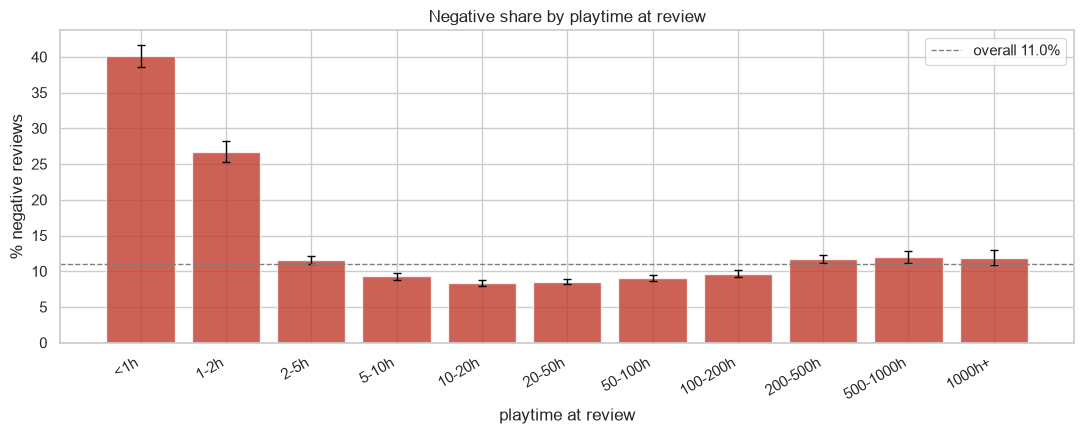

,negatives,reviews,rate,ci_low,ci_high
playtime_group,,,,,
<1h,1554,3879,0.4006,0.3853,0.4161
1-2h,907,3395,0.2672,0.2525,0.2823
2-5h,1361,11821,0.1151,0.1095,0.1210
5-10h,1350,14553,0.0928,0.0882,0.0976
10-20h,1606,19156,0.0838,0.0800,0.0878
20-50h,2218,26057,0.0851,0.0818,0.0886
50-100h,1572,17320,0.0908,0.0866,0.0951
100-200h,1350,14045,0.0961,0.0914,0.1011
200-500h,1480,12680,0.1167,0.1112,0.1224


Observation (groups with at least 30 reviews): the negative share is highest for '<1h' (40.1%) and lowest for '10-20h' (8.4%).


In [13]:
play_edges = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, np.inf]
play_labels = ["<1h", "1-2h", "2-5h", "5-10h", "10-20h", "20-50h", "50-100h",
               "100-200h", "200-500h", "500-1000h", "1000h+"]
df["playtime_group"] = pd.cut(df["playtime_at_review_h"], play_edges, labels=play_labels,
                              include_lowest=True, right=False)
play_rate = E.rate_table(df, "playtime_group")
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_rate(ax, play_rate, overall_neg, "Negative share by playtime at review", "playtime at review", rotate=30)
savefig("11_negative_share_by_playtime")
display(play_rate.round(4))

reliable = play_rate[play_rate["reviews"] >= 30]
top_group = reliable["rate"].idxmax()
low_group = reliable["rate"].idxmin()
print(f"Observation (groups with at least 30 reviews): the negative share is highest for '{top_group}' "
      f"({reliable.loc[top_group, 'rate']:.1%}) and lowest for '{low_group}' ({reliable.loc[low_group, 'rate']:.1%}).")

This figure checks H1 visually. On the full data the relation is **U-shaped rather than a simple decline**: about 40 % of the reviews written in the first hour are negative and about 27 % at 1–2 h, the minimum (≈ 8–9 %) is reached at 10–50 h, and after 200 h the share rises again to ≈ 12 %, slightly above the average. Very early negative reviews fit games that disappoint or do not run at all (Steam refunds are possible only below 2 hours of playtime); long-time players may criticise updates, monetisation or cheaters. This non-linearity explains why the linear correlation of playtime with the target is close to zero (4.3.2) although the groups differ strongly, and it is another reason for the log transformation and for non-linear models in part 2.

### Figure 12 — negative share by review length

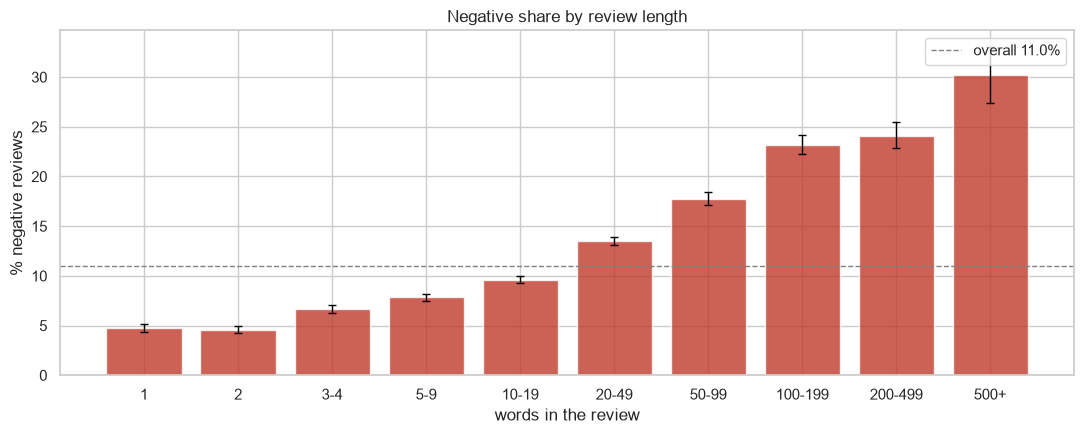

,negatives,reviews,rate,ci_low,ci_high
length_group,,,,,
1,568,11942,0.0476,0.0439,0.0515
2,569,12418,0.0458,0.0423,0.0496
3-4,940,14205,0.0662,0.0622,0.0704
5-9,1669,21282,0.0784,0.0749,0.0821
10-19,2178,22632,0.0962,0.0925,0.1001
20-49,3329,24650,0.1351,0.1308,0.1394
50-99,2242,12620,0.1777,0.1711,0.1844
100-199,1730,7468,0.2317,0.2222,0.2414
200-499,989,4102,0.2411,0.2283,0.2544


Observation (groups with at least 30 reviews): 4.8% negative among the shortest reviews (1 words) vs 30.2% among the longest (500+ words).


In [14]:
len_edges = [0, 1, 2, 4, 9, 19, 49, 99, 199, 499, np.inf]
len_labels = ["1", "2", "3-4", "5-9", "10-19", "20-49", "50-99", "100-199", "200-499", "500+"]
df["length_group"] = pd.cut(df["word_count"], len_edges, labels=len_labels, right=True)
len_rate = E.rate_table(df, "length_group")
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_rate(ax, len_rate, overall_neg, "Negative share by review length", "words in the review")
savefig("12_negative_share_by_length")
display(len_rate.round(4))
reliable_len = len_rate[len_rate["reviews"] >= 30]
print(f"Observation (groups with at least 30 reviews): {reliable_len['rate'].iloc[0]:.1%} negative among the shortest "
      f"reviews ({reliable_len.index[0]} words) vs {reliable_len['rate'].iloc[-1]:.1%} among the longest "
      f"({reliable_len.index[-1]} words).")

### Figure 13 — negative share by boolean features

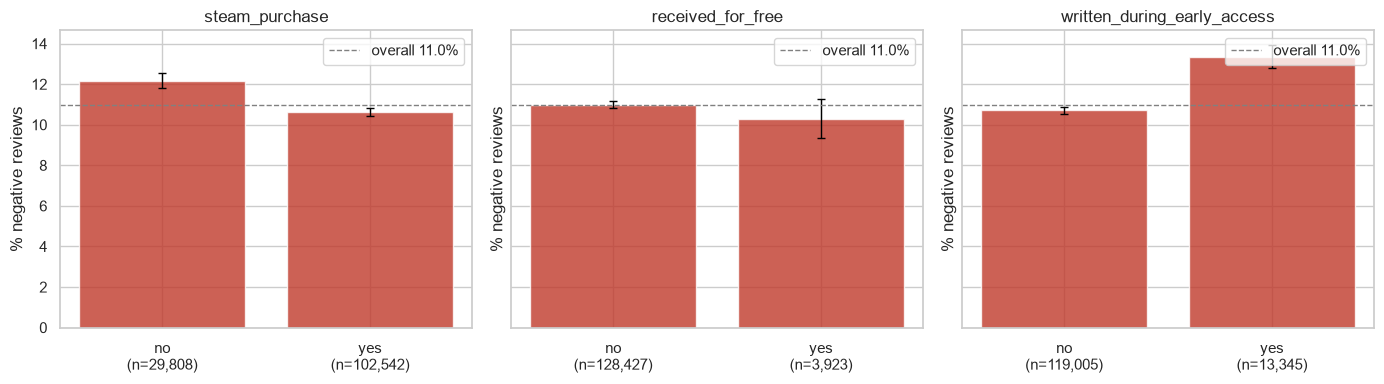

In [15]:
fig, axes = plt.subplots(1, len(C.BOOL_FEATURES), figsize=(14, 4), sharey=True)
for ax, col in zip(axes, C.BOOL_FEATURES):
    tab = E.rate_table(df.assign(**{col: df[col].map({0.0: "no", 1.0: "yes"})}), col)
    tab = tab.reindex([v for v in ["no", "yes"] if v in tab.index])
    plot_rate(ax, tab, overall_neg, col, "")
    ax.set_xticklabels([f"{v}\n(n={n:,})" for v, n in zip(tab.index, tab["reviews"])])
savefig("13_negative_share_by_boolean")

Visual check of H3. A difference between *no* and *yes* matters only if the confidence intervals do not overlap; very small groups (for example free copies) produce wide intervals.

### Figure 14 — negative share by game

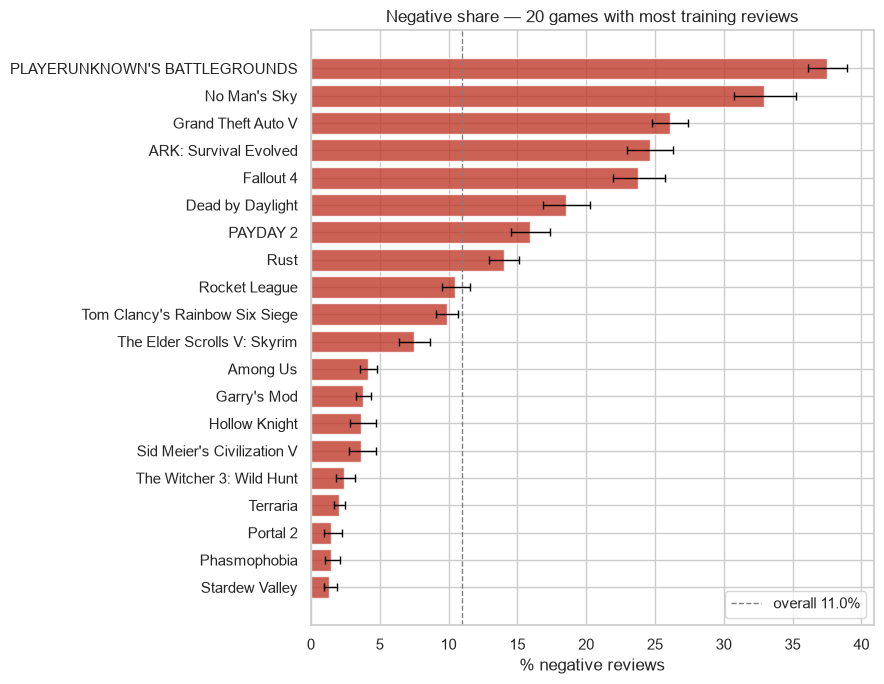

Observation: among these games the negative share ranges from 1.3% (Stardew Valley) to 37.5% (PLAYERUNKNOWN'S BATTLEGROUNDS).


In [16]:
top_games = game_counts.head(20).index
game_rate = E.rate_table(df[df["app_name"].isin(top_games)], "app_name").sort_values("rate")
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(game_rate))
rate = game_rate["rate"].to_numpy() * 100
err = np.vstack([rate - game_rate["ci_low"].to_numpy() * 100, game_rate["ci_high"].to_numpy() * 100 - rate])
ax.barh(y, rate, color="#c0392b", alpha=0.8)
ax.errorbar(rate, y, xerr=err, fmt="none", ecolor="black", capsize=3, lw=1)
ax.axvline(overall_neg * 100, ls="--", color="grey", lw=1, label=f"overall {overall_neg:.1%}")
ax.set_yticks(y)
ax.set_yticklabels(game_rate.index)
ax.set_xlabel("% negative reviews")
ax.set_title("Negative share — 20 games with most training reviews")
ax.legend(loc="lower right")
savefig("14_negative_share_by_game")
print(f"Observation: among these games the negative share ranges from {game_rate['rate'].min():.1%} "
      f"({game_rate['rate'].idxmin()}) to {game_rate['rate'].max():.1%} ({game_rate['rate'].idxmax()}).")

The game a review belongs to is a strong prior for its label: the same words can be written about a well-liked game and about a controversial one, but the base rate of negative reviews differs. This justifies keeping `app_name` as a candidate feature (one-hot encoded).

### Figure 15 — reviews and negative share over time

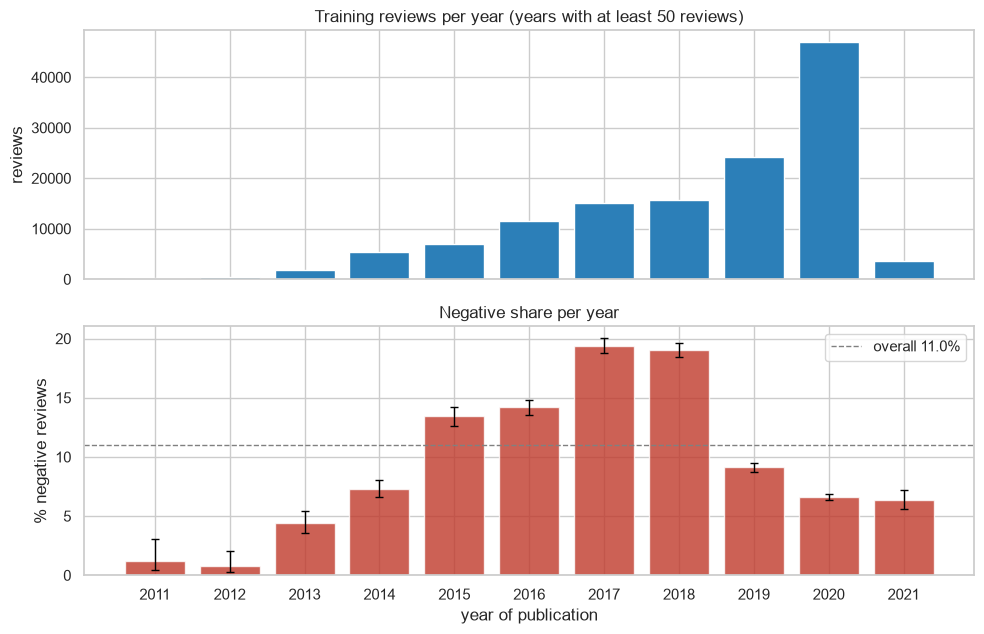

,negatives,reviews,rate,ci_low,ci_high
year,,,,,
2011,4,335,0.0119,0.0047,0.0303
2012,4,505,0.0079,0.0031,0.0202
2013,79,1802,0.0438,0.0353,0.0543
2014,396,5430,0.0729,0.0663,0.0802
2015,941,7008,0.1343,0.1265,0.1425
2016,1648,11606,0.1420,0.1358,0.1485
2017,2928,15106,0.1938,0.1876,0.2002
2018,2986,15693,0.1903,0.1842,0.1965
2019,2212,24285,0.0911,0.0875,0.0948


In [17]:
df["year"] = df["created_at"].dt.year
year_rate = E.rate_table(df.dropna(subset=["year"]).astype({"year": int}), "year")
year_rate = year_rate[year_rate["reviews"] >= 50]
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
axes[0].bar(year_rate.index.astype(str), year_rate["reviews"], color="#2c7fb8")
axes[0].set_ylabel("reviews")
axes[0].set_title("Training reviews per year (years with at least 50 reviews)")
plot_rate(axes[1], year_rate, overall_neg, "Negative share per year", "year of publication")
axes[1].set_xticklabels(year_rate.index.astype(str))
savefig("15_reviews_over_time")
display(year_rate.round(4))

The upper panel shows that the collection is concentrated in recent years: the number of reviews grows steadily and peaks in 2020 (2021 contains only January, the month of data collection). The lower panel shows a clear drift in opinions: the negative share rises to its maximum in 2017–2018 and falls below the average from 2019 (≈ 9 %) and to about 6.5 % in 2020–2021. Part of this pattern may come from the game mix of each year rather than from changing opinions only (for example, PLAYERUNKNOWN'S BATTLEGROUNDS, released in 2017, has the highest negative share among the large games). Such a drift is a reason to keep a review-age feature as a candidate in section 5 and to mention time as a limitation.

### Figure 16 — words that distinguish negative from positive reviews
Weighted log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi & Quinn, 2008). Positive z = the word is typical for negative reviews, negative z = typical for positive reviews. Unlike raw frequency, this score is not dominated by words that are common in both classes (*game*, *the*).

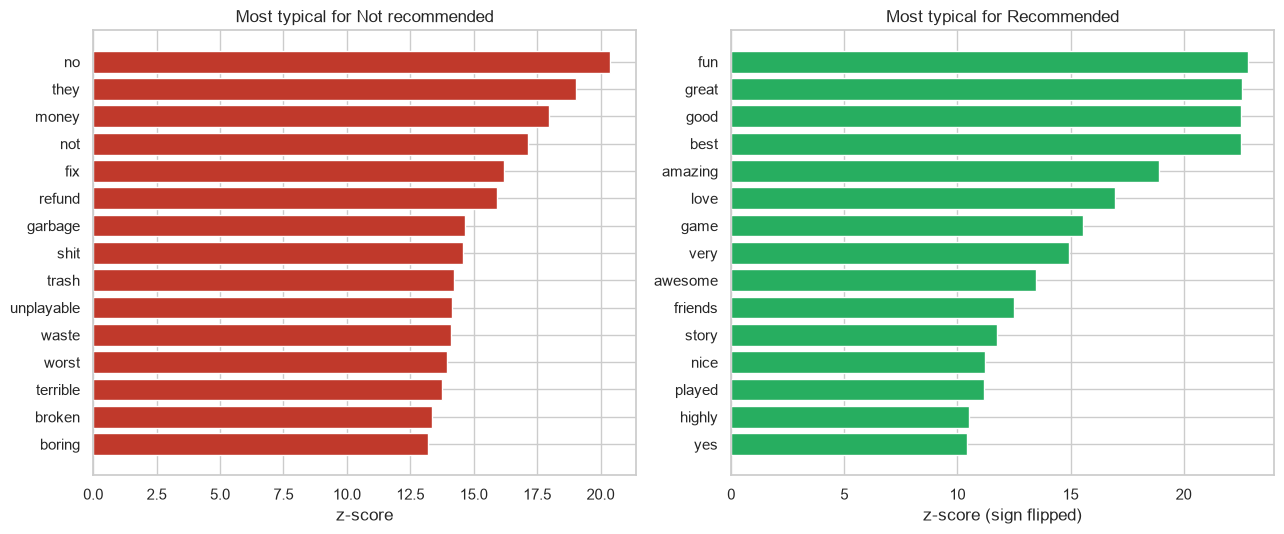

Negative markers: no, they, money, not, fix, refund, garbage, shit, trash, unplayable, waste, worst, terrible, broken, boring
Positive markers: fun, great, good, best, amazing, love, game, very, awesome, friends, story, nice, played, highly, yes


In [18]:
words = E.log_odds_words(df[C.TEXT_CLEAN], df["is_negative"], min_df=20)
top_neg = words[words["z"] > 0].head(15)
top_pos = words[words["z"] < 0].tail(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].barh(top_neg["word"][::-1], top_neg["z"][::-1], color=PALETTE[NEG])
axes[0].set_title("Most typical for Not recommended")
axes[0].set_xlabel("z-score")
axes[1].barh(top_pos["word"][::-1], -top_pos["z"][::-1], color=PALETTE[POS])
axes[1].set_title("Most typical for Recommended")
axes[1].set_xlabel("z-score (sign flipped)")
savefig("16_discriminative_words")
words.to_csv(C.TABLES_DIR / "eda_log_odds_words.csv", index=False)
print("Negative markers:", ", ".join(top_neg["word"]))
print("Positive markers:", ", ".join(top_pos["word"]))

These words are the main reason to expect that text alone can predict the recommendation (RQ1). Negation words in this list show that context matters, which supports using word pairs (bigrams such as *not worth*) in TF-IDF in section 5.

## 4.5 Statistical tests
With tens of thousands of reviews even tiny differences become statistically significant, so every test is reported with an **effect size** and the decision is based on both. All p-values are adjusted with the **Bonferroni** correction for the number of tests (m tests → p × m), significance level α = 0.05.

| Effect size | negligible | small | medium | large |
|---|---|---|---|---|
| rank-biserial r, Cramér's V (df = 1), Spearman ρ | < 0.1 | 0.1–0.3 | 0.3–0.5 | ≥ 0.5 |
| η² (ANOVA) | < 0.01 | 0.01–0.06 | 0.06–0.14 | ≥ 0.14 |

### H1 — negative reviewers have less playtime at the moment of the review
* **One-way ANOVA** on `log1p(playtime at review)` between the two classes (the log makes the groups roughly normal, see figure 08), with **Levene's test** for equal variances and **Welch's t-test** as the version that does not assume equal variances;
* **Mann–Whitney U** on raw minutes as the non-parametric check that needs no distribution assumption.

In [19]:
log_play = np.log1p(df["author_playtime_at_review"])
neg_log = log_play[df["is_negative"] == 1].dropna()
pos_log = log_play[df["is_negative"] == 0].dropna()

f_h1, p_anova_h1 = stats.f_oneway(neg_log, pos_log)
eta_h1 = E.eta_squared([neg_log, pos_log])
lev_h1, p_lev_h1 = stats.levene(neg_log, pos_log, center="median")
t_h1, p_welch_h1 = stats.ttest_ind(neg_log, pos_log, equal_var=False)
mw_h1 = E.mann_whitney(df.loc[df["is_negative"] == 1, "author_playtime_at_review"],
                       df.loc[df["is_negative"] == 0, "author_playtime_at_review"])
med_h1 = df.groupby("label")["playtime_at_review_h"].median()

h1 = pd.DataFrame({
    "statistic": [f_h1, lev_h1, t_h1, mw_h1["U"]],
    "p": [p_anova_h1, p_lev_h1, p_welch_h1, mw_h1["p"]],
    "effect size": [f"eta2 = {eta_h1:.4f}", "-", "-", f"r_rb = {mw_h1['r_rb']:+.3f}"],
}, index=["ANOVA (log1p)", "Levene (log1p)", "Welch t (log1p)", "Mann-Whitney U (raw)"])
h1["p"] = h1["p"].map(E.fmt_p)
display(h1)
print(f"Median playtime at review: {med_h1[NEG]:.1f} h (negative) vs {med_h1[POS]:.1f} h (positive)")
print(f"Probability that a random negative reviewer played longer than a random positive one: {mw_h1['cles']:.3f}")
print("Levene: variances " + ("differ -> Welch's t-test is the valid parametric test"
                              if p_lev_h1 < ALPHA else "do not differ significantly -> ANOVA assumptions hold"))

,statistic,p,effect size
ANOVA (log1p),8.556310e+02,1.72e-187,eta2 = 0.0064
Levene (log1p),2.241204e+03,< 1e-300,-
Welch t (log1p),-2.399918e+01,3.66e-125,-
Mann-Whitney U (raw),7.642688e+08,2.50e-98,r_rb = -0.107


Median playtime at review: 24.3 h (negative) vs 32.8 h (positive)
Probability that a random negative reviewer played longer than a random positive one: 0.447
Levene: variances differ -> Welch's t-test is the valid parametric test


### H2 — negative reviews are longer than positive ones
Mann–Whitney U on the number of words (length is extremely skewed, so a rank test is the appropriate choice).

In [20]:
mw_h2 = E.mann_whitney(df.loc[df["is_negative"] == 1, "word_count"], df.loc[df["is_negative"] == 0, "word_count"])
med_h2 = df.groupby("label")["word_count"].median()
print(f"U = {mw_h2['U']:,.0f}, p = {E.fmt_p(mw_h2['p'])}, rank-biserial r = {mw_h2['r_rb']:+.3f} "
      f"({E.effect_label(mw_h2['r_rb'], 'r')})")
print(f"Median words: {med_h2[NEG]:.0f} (negative) vs {med_h2[POS]:.0f} (positive)")
print(f"Probability that a random negative review is longer than a random positive one: {mw_h2['cles']:.3f}")

U = 1,133,414,711, p = < 1e-300, rank-biserial r = +0.325 (medium)
Median words: 29 (negative) vs 10 (positive)
Probability that a random negative review is longer than a random positive one: 0.662


### H3 — the recommendation rate differs for early-access reviews and for free copies
Chi-square test of independence on 2 × 2 contingency tables, effect size Cramér's V.

In [21]:
h3_rows = []
for col in ["written_during_early_access", "received_for_free"]:
    chi2_value, p_value, dof, v = E.cramers_v(df[col], df["is_negative"])
    h3_rows.append({
        "feature": col,
        "% negative when yes": 100 * df.loc[df[col] == 1, "is_negative"].mean(),
        "% negative when no": 100 * df.loc[df[col] == 0, "is_negative"].mean(),
        "n yes": int((df[col] == 1).sum()),
        "chi2": chi2_value, "p": p_value, "cramers_v": v,
    })
h3 = pd.DataFrame(h3_rows).set_index("feature")
display(h3.assign(p=h3["p"].map(E.fmt_p)).round(4))

,% negative when yes,% negative when no,n yes,chi2,p,cramers_v
feature,,,,,,
written_during_early_access,13.3608,10.7071,13345,86.4881,1.41e-20,0.0256
received_for_free,10.2728,10.9961,3923,2.0388,1.53e-01,0.0039


### Additional ANOVA — does review length differ between playtime groups?
Players are split into four equal-sized groups (quartiles) by playtime at review, and the mean of `log1p(word_count)` is compared with **one-way ANOVA** (k = 4 groups). Levene's test checks the equal-variance assumption, **Kruskal–Wallis** is the non-parametric alternative. This answers whether experienced players write differently, which matters because length and playtime could otherwise carry the same information.

,statistic,p
one-way ANOVA,87.716874,1.07e-56
Levene,58.340035,1.11e-37
Kruskal-Wallis,200.029275,4.16e-43


,count,median,mean
playtime_quartile,,,
Q1 (least),33102,11.0,32.5
Q2,33080,12.0,40.6
Q3,33081,13.0,44.4
Q4 (most),33087,11.0,41.4


eta2 = 0.0020 (negligible): playtime group explains 0.20% of the variance of log review length


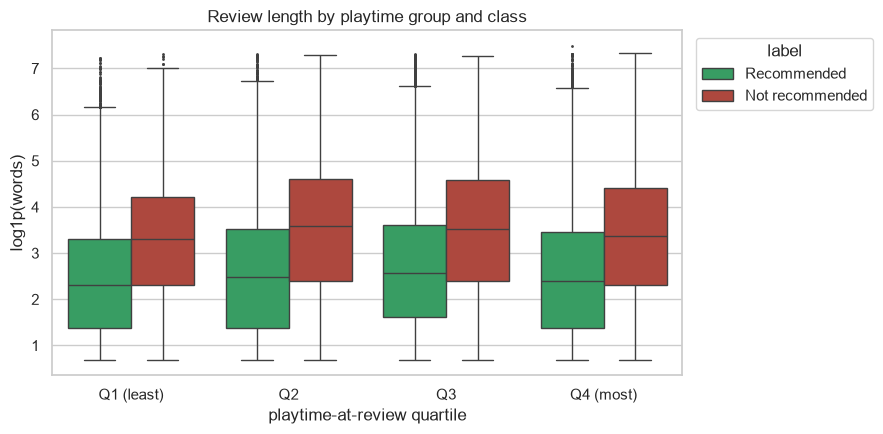

In [22]:
df["playtime_quartile"] = pd.qcut(df["author_playtime_at_review"], 4, labels=["Q1 (least)", "Q2", "Q3", "Q4 (most)"],
                                  duplicates="drop")
df["log_words"] = np.log1p(df["word_count"])
quart = df.dropna(subset=["playtime_quartile"])
groups = [g["log_words"].to_numpy() for _, g in quart.groupby("playtime_quartile", observed=True)]
f_len, p_anova_len = stats.f_oneway(*groups)
lev_len, p_lev_len = stats.levene(*groups, center="median")
h_len, p_kw_len = stats.kruskal(*groups)
eta_len = E.eta_squared(groups)

anova_len = pd.DataFrame({
    "statistic": [f_len, lev_len, h_len],
    "p": [E.fmt_p(p_anova_len), E.fmt_p(p_lev_len), E.fmt_p(p_kw_len)],
}, index=["one-way ANOVA", "Levene", "Kruskal-Wallis"])
display(anova_len)
display(df.groupby("playtime_quartile", observed=True)["word_count"].agg(["count", "median", "mean"]).round(1))
print(f"eta2 = {eta_len:.4f} ({E.effect_label(eta_len, 'eta2')}): playtime group explains "
      f"{100 * eta_len:.2f}% of the variance of log review length")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=quart, x="playtime_quartile", y="log_words",
            hue="label", hue_order=[POS, NEG], palette=PALETTE, fliersize=1, ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1))
ax.set_xlabel("playtime-at-review quartile")
ax.set_ylabel("log1p(words)")
ax.set_title("Review length by playtime group and class")
savefig("17_length_by_playtime_quartile")

### 4.5.5 All tests with Bonferroni correction and verdicts

In [23]:
chi_game, p_game, dof_game, v_game = E.cramers_v(games_grouped, df["is_negative"])
early, free = h3.loc["written_during_early_access"], h3.loc["received_for_free"]

tests = pd.DataFrame([
    ("H1", "ANOVA log1p(playtime) ~ class", f_h1, p_anova_h1, eta_h1, "eta2"),
    ("H1", "Mann-Whitney playtime ~ class", mw_h1["U"], mw_h1["p"], mw_h1["r_rb"], "r"),
    ("H2", "Mann-Whitney words ~ class", mw_h2["U"], mw_h2["p"], mw_h2["r_rb"], "r"),
    ("H3", "Chi-square early access x class", early["chi2"], early["p"], early["cramers_v"], "v"),
    ("H3", "Chi-square free copy x class", free["chi2"], free["p"], free["cramers_v"], "v"),
    ("extra", "ANOVA log1p(words) ~ playtime quartile", f_len, p_anova_len, eta_len, "eta2"),
    ("extra", "Chi-square game x class", chi_game, p_game, v_game, "v"),
], columns=["hypothesis", "test", "statistic", "p", "effect_size", "kind"])
tests["p_bonferroni"] = E.bonferroni(tests["p"].fillna(1.0))
tests["significant"] = tests["p_bonferroni"] < ALPHA
tests["effect"] = [E.effect_label(v, k) if pd.notna(v) else "n/a" for v, k in zip(tests["effect_size"], tests["kind"])]
tests.drop(columns="kind").to_csv(C.TABLES_DIR / "eda_statistical_tests.csv", index=False)
display(tests.drop(columns="kind").assign(p=tests["p"].map(E.fmt_p), p_bonferroni=tests["p_bonferroni"].map(E.fmt_p))
        .round(4))


def verdict(significant, direction_ok, effect):
    if not significant:
        return "NOT SUPPORTED (no significant difference after correction)"
    if not direction_ok:
        return f"REJECTED (significant, but in the opposite direction; effect {effect})"
    return f"SUPPORTED (effect {effect})"


by_test = tests.set_index("test")
sig = by_test["significant"]
h3_tests = ["Chi-square early access x class", "Chi-square free copy x class"]
h3_strongest = by_test.loc[h3_tests, "effect_size"].abs().idxmax()
verdicts = {
    "H1": verdict(sig["ANOVA log1p(playtime) ~ class"] and sig["Mann-Whitney playtime ~ class"],
                  med_h1[NEG] < med_h1[POS], by_test.loc["Mann-Whitney playtime ~ class", "effect"]),
    "H2": verdict(sig["Mann-Whitney words ~ class"], med_h2[NEG] > med_h2[POS],
                  by_test.loc["Mann-Whitney words ~ class", "effect"]),
}
h3_names = {"Chi-square early access x class": "early-access reviews", "Chi-square free copy x class": "free copies"}
h3_significant = [h3_names[t] for t in h3_tests if sig[t]]
if len(h3_significant) == len(h3_tests):
    verdicts["H3"] = f"SUPPORTED (effect {by_test.loc[h3_strongest, 'effect']})"
elif h3_significant:
    only = [t for t in h3_tests if sig[t]][0]
    verdicts["H3"] = (f"PARTIALLY SUPPORTED (significant only for {h3_significant[0]}; "
                      f"effect {by_test.loc[only, 'effect']})")
else:
    verdicts["H3"] = "NOT SUPPORTED (no significant difference after correction)"
for h, v in verdicts.items():
    print(f"{h}: {v}")

,hypothesis,test,statistic,p,effect_size,p_bonferroni,significant,effect
0,H1,ANOVA log1p(playtime) ~ class,8.556310e+02,1.72e-187,0.0064,1.21e-186,True,negligible
1,H1,Mann-Whitney playtime ~ class,7.642688e+08,2.50e-98,-0.1069,1.75e-97,True,small
2,H2,Mann-Whitney words ~ class,1.133415e+09,< 1e-300,0.3245,< 1e-300,True,medium
3,H3,Chi-square early access x class,8.648810e+01,1.41e-20,0.0256,9.84e-20,True,negligible
4,H3,Chi-square free copy x class,2.038800e+00,1.53e-01,0.0039,1.00e+00,False,negligible
5,extra,ANOVA log1p(words) ~ playtime quartile,8.771690e+01,1.07e-56,0.0020,7.46e-56,True,negligible
6,extra,Chi-square game x class,1.595646e+04,< 1e-300,0.3472,< 1e-300,True,medium


H1: SUPPORTED (effect small)
H2: SUPPORTED (effect medium)
H3: PARTIALLY SUPPORTED (significant only for early-access reviews; effect negligible)


**How to read the verdicts.** *Supported* means the difference is significant after the Bonferroni correction **and** goes in the predicted direction. H3 has two parts (early access and free copies); it is *partially supported* when only one of them is significant. The effect-size column then says whether the difference is practically important: with this sample size a "significant but negligible" result means the groups differ only slightly and the feature alone is a weak predictor; it can still help in combination with text.

## 4.6 Conclusions of the EDA

In [24]:
def direction(a, b, more, less):
    return more if a > b else less


rho_allowed = allowed["spearman"]
best_allowed = rho_allowed.abs().idxmax()
best_effect = E.effect_label(rho_allowed[best_allowed], "rho")
pearson_gap = (target_corr["pearson (raw)"] - target_corr["pearson (log1p)"]).abs()
year_first, year_last = (year_rate.index.min(), year_rate.index.max()) if len(year_rate) else (None, None)
game_effect = E.effect_label(v_game, "v")
play_ok = play_rate[play_rate["reviews"] >= 30]
first_g, low_g, last_g = play_ok.index[0], play_ok["rate"].idxmin(), play_ok.index[-1]
first_r, low_r, last_r = play_ok.loc[first_g, "rate"], play_ok.loc[low_g, "rate"], play_ok.loc[last_g, "rate"]
u_shape = first_r > low_r + 0.02 and last_r > low_r + 0.02
conclusions = [
    ("Class imbalance",
     f"Only {overall_neg:.1%} of the training reviews are negative ({(1 - overall_neg) / overall_neg:.1f} positive per negative). "
     "Accuracy is misleading; models are compared with F1-macro and PR-AUC of the negative class and trained with class weights."),
    ("H1 - playtime",
     f"Negative reviewers had a median of {med_h1[NEG]:.1f} h at the time of the review vs {med_h1[POS]:.1f} h for positive reviewers "
     f"({direction(med_h1[NEG], med_h1[POS], 'more', 'less')} playtime); ANOVA eta2 = {eta_h1:.3f}, rank-biserial r = {mw_h1['r_rb']:+.3f} "
     f"({E.effect_label(mw_h1['r_rb'], 'r')}). H1 {verdicts['H1']}."),
    ("Playtime pattern",
     f"Negative share by playtime at review: {first_r:.1%} for '{first_g}'"
     + (f", minimum {low_r:.1%} for '{low_g}', {last_r:.1%} for '{last_g}'. " if low_g != last_g
        else f", lowest ({low_r:.1%}) in the longest group '{last_g}'. ")
     + ("The relation is U-shaped: players who quit very early and very experienced players are both more negative than "
        "mid-range players, so the linear correlation is close to zero although the groups differ strongly."
        if u_shape else ("The negative share mostly decreases with playtime." if first_r > last_r
                         else "The negative share mostly increases with playtime."))),
    ("H2 - length",
     f"Negative reviews have a median of {med_h2[NEG]:.0f} words vs {med_h2[POS]:.0f} for positive "
     f"({direction(med_h2[NEG], med_h2[POS], 'longer', 'shorter')}); r = {mw_h2['r_rb']:+.3f} "
     f"({E.effect_label(mw_h2['r_rb'], 'r')}). H2 {verdicts['H2']}. Review length is a useful engineered feature."),
    ("H3 - early access / free copies",
     f"Early-access reviews: {early['% negative when yes']:.1f}% negative vs {early['% negative when no']:.1f}% otherwise "
     f"(V = {early['cramers_v']:.3f}); free copies: {free['% negative when yes']:.1f}% vs {free['% negative when no']:.1f}% "
     f"(V = {free['cramers_v']:.3f}). H3 {verdicts['H3']}."),
    ("Game effect",
     f"The negative share ranges from {game_rate['rate'].min():.1%} to {game_rate['rate'].max():.1%} among the 20 largest games; "
     f"Cramer's V = {v_game:.3f} ({game_effect}). "
     + ("app_name is kept as a one-hot candidate feature." if game_effect not in ("negligible", "n/a")
        else "The game alone says little about the label; app_name is still tested as a candidate in section 5.")),
    ("Text signal",
     f"Clear sentiment vocabulary separates the classes (negative markers: {', '.join(top_neg['word'].head(6))}; "
     f"positive markers: {', '.join(top_pos['word'].head(6))}). Text is expected to be the main predictor (RQ1); "
     "negations motivate bigrams in TF-IDF."),
    ("Heavy tails",
     f"{len(heavy)} of {len(NUMERIC)} numeric features have skewness > 1; Pearson's r with the target changes by up to "
     f"{pearson_gap.max():.2f} ({pearson_gap.idxmax()}) between raw and log1p values. "
     "The log1p transformation and rank-based statistics are justified."),
    ("Correlations and leakage",
     f"Among features known at review time the strongest relation with the target is {best_allowed} "
     f"(rho = {rho_allowed[best_allowed]:+.3f}, {best_effect}); "
     + ("numeric features alone are weak predictors, the text has to carry most of the signal. "
        if best_effect in ("negligible", "small") else "it is a useful predictor next to the text. ")
     + "Post-publication columns (votes, comments, later playtime) stay excluded from the model even where they correlate."),
]
if year_first is not None and year_first != year_last:
    span = year_rate["rate"].max() - year_rate["rate"].min()
    conclusions.append((
        "Time",
        f"The yearly negative share varies between {year_rate['rate'].min():.1%} and {year_rate['rate'].max():.1%} "
        f"({year_first}: {year_rate.loc[year_first, 'rate']:.1%}, {year_last}: {year_rate.loc[year_last, 'rate']:.1%}); "
        + ("opinions drift over time, so review age is a candidate feature and time is a limitation of a single 2021 snapshot."
           if span > 0.03 else "the share is fairly stable over time.")))
conclusions = pd.DataFrame(conclusions, columns=["topic", "conclusion"])
conclusions.index = conclusions.index + 1
conclusions.to_csv(C.TABLES_DIR / "eda_conclusions.csv")
with pd.option_context("display.max_colwidth", None):
    display(conclusions.style.format(escape="html").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,topic,conclusion
1,Class imbalance,Only 11.0% of the training reviews are negative (8.1 positive per negative). Accuracy is misleading; models are compared with F1-macro and PR-AUC of the negative class and trained with class weights.
2,H1 - playtime,"Negative reviewers had a median of 24.3 h at the time of the review vs 32.8 h for positive reviewers (less playtime); ANOVA eta2 = 0.006, rank-biserial r = -0.107 (small). H1 SUPPORTED (effect small)."
3,Playtime pattern,"Negative share by playtime at review: 40.1% for '<1h', minimum 8.4% for '10-20h', 11.9% for '1000h+'. The relation is U-shaped: players who quit very early and very experienced players are both more negative than mid-range players, so the linear correlation is close to zero although the groups differ strongly."
4,H2 - length,Negative reviews have a median of 29 words vs 10 for positive (longer); r = +0.325 (medium). H2 SUPPORTED (effect medium). Review length is a useful engineered feature.
5,H3 - early access / free copies,Early-access reviews: 13.4% negative vs 10.7% otherwise (V = 0.026); free copies: 10.3% vs 11.0% (V = 0.004). H3 PARTIALLY SUPPORTED (significant only for early-access reviews; effect negligible).
6,Game effect,The negative share ranges from 1.3% to 37.5% among the 20 largest games; Cramer's V = 0.347 (medium). app_name is kept as a one-hot candidate feature.
7,Text signal,"Clear sentiment vocabulary separates the classes (negative markers: no, they, money, not, fix, refund; positive markers: fun, great, good, best, amazing, love). Text is expected to be the main predictor (RQ1); negations motivate bigrams in TF-IDF."
8,Heavy tails,9 of 10 numeric features have skewness > 1; Pearson's r with the target changes by up to 0.26 (votes_helpful) between raw and log1p values. The log1p transformation and rank-based statistics are justified.
9,Correlations and leakage,"Among features known at review time the strongest relation with the target is word_count (rho = -0.176, small); numeric features alone are weak predictors, the text has to carry most of the signal. Post-publication columns (votes, comments, later playtime) stay excluded from the model even where they correlate."
10,Time,"The yearly negative share varies between 0.8% and 19.4% (2011: 1.2%, 2021: 6.4%); opinions drift over time, so review age is a candidate feature and time is a limitation of a single 2021 snapshot."


### Implications for the next steps
1. **Metrics and imbalance:** F1-macro, recall and PR-AUC of the negative class; class weights; stratified splits (already done).
2. **Text is the main input:** TF-IDF with unigrams and bigrams, without removing negations from the stop-word list.
3. **Engineered features (section 5):** review length, punctuation and capitals (emotion), negations, reviewer activity and review age — they summarise effects seen above in a form that a linear model can use.
4. **Transformations:** `log1p` for counts and playtime, scaling, one-hot for games — as implemented in the preprocessing pipeline.
5. **Leakage:** votes, comments, later playtime and edit dates are strongly related to other columns but are not available when a review is written, so they remain excluded.